# **Leave You on The Back of the Earth**


 <img src="https://drive.google.com/uc?id=1svDWKxg_1g4YJ9JjkXt3WGGEQqwHIYLa" align=right>

Sebelum memejamkan mata untuk tidur, Anda berpikir bahwa hari esok pasti akan jadi hari yang normal. Nyatanya, begitu Anda membuka mata, Anda bertatapan dengan seorang perempuan berpakaian aneh. Dia mulai berbicara dalam bahasa yang asing, lalu berhenti sebentar. Dia memulai lagi, "Oh ya, kamu tidak bisa mengerti bahasa kami ya? Saya Ura, salam kenal! Sebenarnya bahasa kami adalah sejenis bahasa bernada, dengan 4 nada bernama "Chi", "Kyuuno", "Ura" dan "Nya". Masing-masing suku kata di bahasa kami memiliki tepat 1 nada antara "Chi", "Kyuuno", "Ura" dan "Nya". Apa Anda mau coba untuk menebaknya? Ayo!"

Dalam kata lain, task ini ada 2 bagian.

# Bagian 1: Klasifikasi Nada Tepat 1 Suku Kata
Anda diberi training data sebanyak 50 sample audio yang masing-masing memuat tepat 1 suku kata, dan tugas Anda adalah untuk memberi label audio pada file audio yang lainnya.
# Bagian 2: Klasifikasi Nada 2 Sampai 4 Suku Kata
Anda harus mengklasifikasi file audio yang memuat tepat 2, 3 atau 4 suku kata. Dalam bagian 2, Anda harus:
1) Mengidentifikasi file audio tersebut memuat berapa banyak suku kata.
2) Mengidentifikasi nada dari masing-masing suku kata.
Anda tidak diberi tambahan training data untuk bagian 2.

# Penilaian

Skor resmi berada pada rentang 0–1 dan dihitung langsung sebagai:

$$N = 0{,}67 \times \operatorname{F1Macro}_{\text{Bagian 1}}
   + 0{,}11 \times \operatorname{AkurasiJumlahSukuKata}_{\text{Bagian 2}}
   + 0{,}22 \times \operatorname{AkurasiUrutanNada}_{\text{Bagian 2}}$$

- **F1 macro Bagian 1** memberi bobot sama kepada keempat kelas nada.
- **Akurasi jumlah suku kata** bernilai benar jika jumlah 2–4 suku kata tepat.
- **Akurasi urutan nada** bernilai benar hanya jika seluruh urutan nada tepat.

Tidak ada normalisasi terhadap nilai peserta terbaik.


# 1.1 Persiapan Data

Dataset sudah tersedia melalui Kaggle. Sel berikut mencari folder data secara
otomatis tanpa mengunduh berkas atau mengakses `solution.csv`.


In [1]:
# Impor pustaka yang dipakai pada notebook asli.
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.metrics import f1_score

try:
    import librosa
    import librosa.display
except ImportError:
    librosa = None
    print("librosa tidak tersedia; visualisasi audio akan dilewati.")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

def cari_folder_data(berkas_wajib):
    """Cari folder dataset pada komputer lokal atau Kaggle."""
    kandidat = [Path("kaggle_data"), Path("../kaggle_data"), Path(".")]
    folder_kaggle = Path("/kaggle/input")
    if folder_kaggle.exists():
        kandidat.extend(path.parent for path in folder_kaggle.rglob(berkas_wajib))
    for folder in kandidat:
        if (folder / berkas_wajib).exists() and (folder / "sample_submission.csv").exists():
            return folder
    raise FileNotFoundError(f"Dataset Kaggle dengan berkas {berkas_wajib} tidak ditemukan")


JALUR_SUBMISSION = (
    Path("/kaggle/working/submission.csv")
    if Path("/kaggle/working").exists()
    else Path("submission.csv")
)

DATA_DIR = cari_folder_data("test.csv")


File yang digunakan:

- `train.csv`: 50 audio satu suku kata berlabel;
- `val.csv`: 21 audio berlabel untuk validasi lokal;
- `test.csv`: seluruh audio Bagian 1 dan Bagian 2 dengan kolom `part`;
- `sample_submission.csv`: format gabungan `id`, `suku_kata`, dan `nada`;
- folder `audio/`: seluruh berkas MP3 yang dirujuk oleh `audio_path`.


In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
val = pd.read_csv(DATA_DIR / "val.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("Data training:")
display(train.head())
print("Bentuk data:", train.shape, val.shape, test.shape)


Data training:


,id,nada,audio_path
0,0,Chi,audio/train/0.mp3
1,1,Ura,audio/train/1.mp3
2,2,Chi,audio/train/2.mp3
3,3,Chi,audio/train/3.mp3
4,4,Kyuuno,audio/train/4.mp3


Bentuk data: (50, 3) (21, 3) (229, 3)


#2.1 Eksplorasi Data


Training Data:


,id
count,50.00000
mean,24.50000
std,14.57738
min,0.00000
25%,12.25000
50%,24.50000
75%,36.75000
max,49.00000


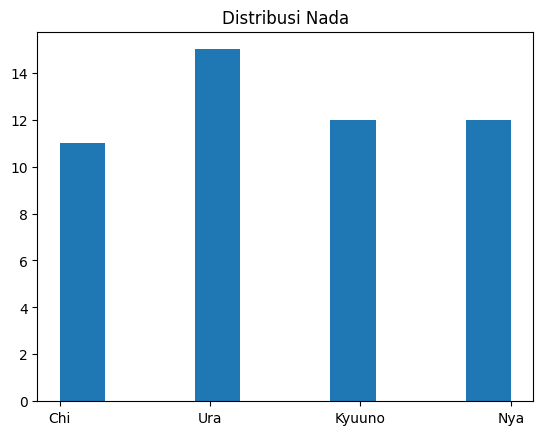

In [4]:
print("Training Data:")
display(train.describe())
plt.hist(train['nada'])
plt.title("Distribusi Nada")
plt.show()


#2.2 Visualisasi Data Audio Menggunakan Librosa


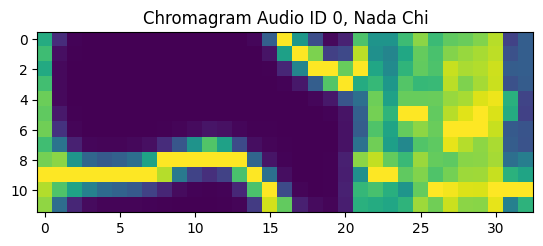

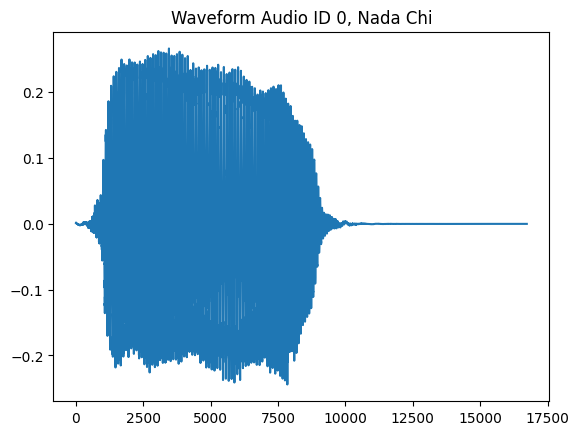

In [5]:
baris = train.iloc[0]
id_audio = int(baris["id"])
jalur_audio = DATA_DIR / baris["audio_path"]

if librosa is None:
    print("Visualisasi dilewati karena librosa tidak tersedia.")
else:
    # Tampilkan chromagram audio.
    y, sr = librosa.load(jalur_audio)
    chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
    plt.imshow(chromagram)
    plt.title(f"Chromagram Audio ID {id_audio}, Nada {baris['nada']}")
    plt.show()

    # Tampilkan waveform audio.
    fig, ax = plt.subplots()
    ax.plot(y)
    ax.set(title=f"Waveform Audio ID {id_audio}, Nada {baris['nada']}")
    plt.show()


16728


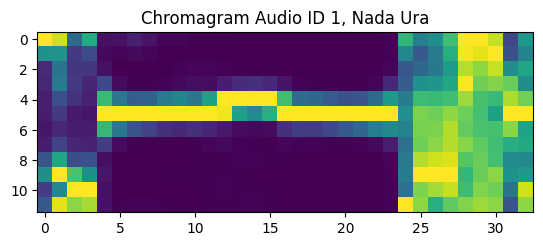

In [6]:
baris = train.iloc[1]
id_audio = int(baris["id"])
jalur_audio = DATA_DIR / baris["audio_path"]
y, sr = librosa.load(jalur_audio)
print(len(y))
chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
plt.imshow(chromagram)
plt.title(f"Chromagram Audio ID {id_audio}, Nada {baris['nada']}")
plt.show()

18456


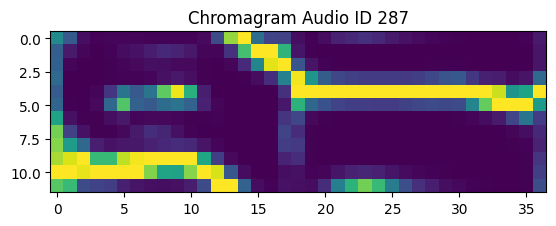

In [7]:
baris = test.iloc[216]
id_audio = int(baris["id"])
jalur_audio = DATA_DIR / baris["audio_path"]
y, sr = librosa.load(jalur_audio)
print(len(y))
chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
plt.imshow(chromagram)
plt.title(f"Chromagram Audio ID {id_audio}")
plt.show()

16728


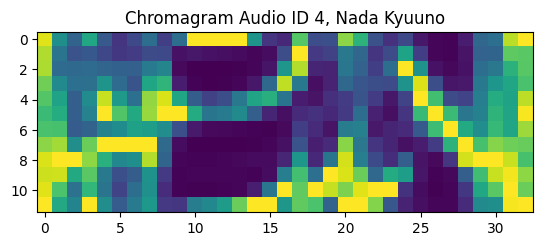

In [8]:
baris = train.iloc[4]
id_audio = int(baris["id"])
jalur_audio = DATA_DIR / baris["audio_path"]
y, sr = librosa.load(jalur_audio)
print(len(y))
chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
plt.imshow(chromagram)
plt.title(f"Chromagram Audio ID {id_audio}, Nada {baris['nada']}")
plt.show()

16728


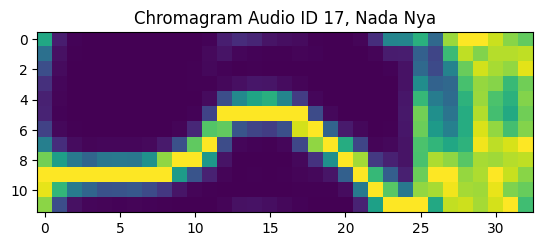

In [10]:
baris = train.iloc[17]
id_audio = int(baris["id"])
jalur_audio = DATA_DIR / baris["audio_path"]
y, sr = librosa.load(jalur_audio)
print(len(y))
chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
plt.imshow(chromagram)
plt.title(f"Chromagram Audio ID {id_audio}, Nada {baris['nada']}")
plt.show()

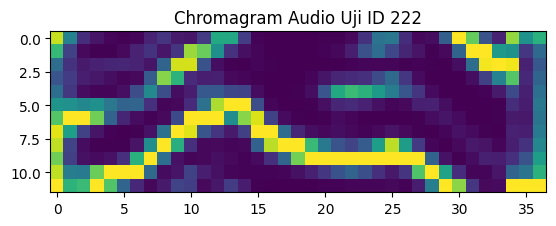

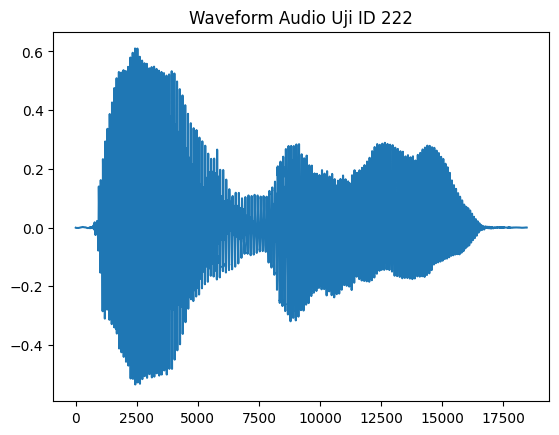

In [11]:
baris = test.loc[test["part"].eq(2)].iloc[0]
id_audio = int(baris["id"])
jalur_audio = DATA_DIR / baris["audio_path"]
if librosa is None:
    print("Visualisasi dilewati karena librosa tidak tersedia.")
else:
    y, sr = librosa.load(jalur_audio)
    chromagram = librosa.feature.chroma_stft(y=y, sr=sr)
    plt.imshow(chromagram)
    plt.title(f"Chromagram Audio Uji ID {id_audio}")
    plt.show()

    fig, ax = plt.subplots()
    ax.plot(y)
    ax.set(title=f"Waveform Audio Uji ID {id_audio}")
    plt.show()


In [12]:
#Silakan melakukan eksplorasi data lebih mendalam


# 3.1 Fungsi Bantu


In [13]:
def f1_macro(y_true: list[str], y_pred: list[str]) -> float:
    """Hitung F1 macro untuk empat kelas nada."""
    return f1_score(
        y_true,
        y_pred,
        labels=["Chi", "Kyuuno", "Ura", "Nya"],
        average="macro",
        zero_division=0,
    )


def marker1(y_pred):
    """Tampilkan perkiraan nilai Bagian 1 pada data validasi."""
    f1 = f1_macro(list(val["nada"]), y_pred)
    skor = f1 * 0.67
    print(f"Nilai F1 macro pada validasi: {f1:.4f}")
    print(f"Perkiraan kontribusi Bagian 1: {skor:.4f}")
    print("Tidak tersedia perkiraan nilai lokal untuk Bagian 2.")


jalur_audio_by_id = {
    int(row.id): DATA_DIR / row.audio_path
    for tabel in (train, val, test)
    for row in tabel.itertuples()
}


In [14]:
class standardscaler:
    def __init__(self):
        self.mean = None
        self.std = None
    def fit(self, x):
        x = np.asarray(x)
        self.mean = np.mean(x, axis=0)
        self.std = np.std(x, axis=0)
        self.std[self.std==0] = 1
        return self
    def transform(self, x):
        x = np.asarray(x)
        z = (x-self.mean)/self.std
        return z

In [15]:
def accuracy_score(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    t = 0
    for i in range(len(y)):
        if x[i] == y[i]:
            t+=1
    return float(t/len(y))

# 4.1 Baseline


In [16]:
class knnc:
    def __init__(self, k=9): #3: 0.50, 5: 0.55, 7: 0.58 9: 0.46
        self.k = k
    def fit(self, x,y):
        self.x=np.asarray(x)
        self.y=np.asarray(y)
    def predict(self, x):
        return [self.pred_one(xa) for xa in x]
    def pred_one(self, x):
        dis = np.sqrt(np.sum((self.x-x)**2, axis=1))
        indices = np.argsort(dis)[:self.k]
        label = self.y[indices]
        return np.argmax(np.bincount(label.reshape(-1)))

In [164]:
def preprocess_audio(y, sr):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    stft = librosa.feature.chroma_stft(y=y, sr=sr)
    zcr = librosa.feature.spectral_bandwidth(y=y)
    mean_mfcc = np.mean(mfcc, axis=1)
    mean_stft = np.mean(stft, axis=1)
    std_mfcc = np.std(stft, axis=1)
    std_stft = np.std(stft, axis=1)
    mean_cens = np.mean(zcr)
    std_cens = np.std(zcr)
    ret = np.hstack((mean_mfcc, mean_stft, std_mfcc, std_stft, std_cens))
    return ret

In [165]:
y,sr = librosa.load(f"{DATA_DIR}/{train.iloc[0]["audio_path"]}")
lsdata = []
for idx, r in train.iterrows():
    y,sr = librosa.load(f"{DATA_DIR}/{r["audio_path"]}")
    pre = preprocess_audio(y, sr)
    lsdata.append(pre)

In [166]:
lsdata = np.asarray(lsdata)
lsdata.shape

(50, 57)

In [167]:
# scaler = standardscaler()
# scaler.fit(lsdata)
# lsdata = scaler.transform(lsdata)

In [172]:
MAP = {"Chi":1, "Ura":2, "Kyuuno":3, "Nya":4}
REVMAP = {1:"Chi", 2:"Ura", 3:"Kyuuno", 4:"Nya"}
trainmod = train.copy()
trainmod = trainmod.replace(MAP)
model1 = knnc(k=7)
model1.fit(lsdata, trainmod["nada"])

/tmp/ipykernel_58/2412471486.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  trainmod = trainmod.replace(MAP)


In [169]:
accuracy_score(model1.predict(lsdata), trainmod["nada"])

0.52

In [170]:
np.random.seed(RANDOM_SEED)

def predictor1(id_audio: int) -> str:
    """Baseline acak untuk satu nada sambil mempertahankan ekstraksi fitur asli."""
    y, sr = librosa.load(jalur_audio_by_id[int(id_audio)])
    pre = preprocess_audio(y, sr)
    ans = model1.predict([pre])
    ans = REVMAP[ans[0]]
    return str(ans)


id_bagian1 = test.loc[test["part"].eq(1), "id"].astype(int).tolist()
preds = [predictor1(id_audio) for id_audio in id_bagian1]
validation = [predictor1(int(id_audio)) for id_audio in val["id"]]
marker1(validation)


Nilai F1 macro pada validasi: 0.5045
Perkiraan kontribusi Bagian 1: 0.3380
Tidak tersedia perkiraan nilai lokal untuk Bagian 2.


In [161]:
# Hasil sementara Bagian 1.
submission1 = pd.DataFrame({
    "id": id_bagian1,
    "suku_kata": 1,
    "nada": [[nada] for nada in preds],
})
display(submission1.head())


,id,suku_kata,nada
0,71,1,[Kyuuno]
1,72,1,[Chi]
2,73,1,[Nya]
3,74,1,[Nya]
4,75,1,[Kyuuno]


In [171]:
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

def predictor2(id_audio: int) -> tuple[int, list[str]]:
    """Baseline Bagian 2: dua suku kata dengan nada acak."""
    y, sr = librosa.load(jalur_audio_by_id[int(id_audio)])
    if len(y) <= 21336:
        jumlah_suku_kata = 2
        y1 = y[:int(np.round(len(y)/2))]
        y2 = y[int(np.round(len(y)/2)):]
        pre1 = preprocess_audio(y1, sr)
        pre2 = preprocess_audio(y2, sr)
        w1 = model1.predict([pre1])[0]
        w2 = model1.predict([pre2])[0]
        nada = [REVMAP[w1],REVMAP[w2]]
    elif len(y) <=25944:
        jumlah_suku_kata = 3
        y1 = y[:int(np.round(len(y)/3))]
        y2 = y[int(np.round(len(y)/3)):int(np.round(2*len(y)/3))]
        y3 = y[int(np.round(2*len(y)/3)):]
        pre1 = preprocess_audio(y1, sr)
        pre2 = preprocess_audio(y2, sr)
        pre3 = preprocess_audio(y3, sr)
        w1 = model1.predict([pre1])[0]
        w2 = model1.predict([pre2])[0]
        w3 = model1.predict([pre3])[0]
        nada = [REVMAP[w1],REVMAP[w2],REVMAP[w3]]
    else:
        jumlah_suku_kata = 4
        y1 = y[:int(np.round(len(y)/4))]
        y2 = y[int(np.round(len(y)/4)):int(np.round(2*len(y)/4))]
        y3 = y[int(np.round(2*len(y)/4)):int(np.round(3*len(y)/4))]
        y4 = y[int(np.round(3*len(y)/4)):]
        pre1 = preprocess_audio(y1, sr)
        pre2 = preprocess_audio(y2, sr)
        pre3 = preprocess_audio(y3, sr)
        pre4 = preprocess_audio(y4, sr)
        w1 = model1.predict([pre1])[0]
        w2 = model1.predict([pre2])[0]
        w3 = model1.predict([pre3])[0]
        w4 = model1.predict([pre4])[0]
        nada = [REVMAP[w1],REVMAP[w2],REVMAP[w3],REVMAP[w4]]


    return jumlah_suku_kata, nada


id_bagian2 = test.loc[test["part"].eq(2), "id"].astype(int).tolist()
hasil_bagian2 = [predictor2(id_audio) for id_audio in id_bagian2]
suku_kata = [hasil[0] for hasil in hasil_bagian2]
nada2 = [hasil[1] for hasil in hasil_bagian2]


In [163]:
# Gabungkan kedua bagian mengikuti urutan sample_submission.csv.
submission2 = pd.DataFrame({
    "id": id_bagian2,
    "suku_kata": suku_kata,
    "nada": nada2,
})
NAMA_FILE = "submission14.csv"
JALUR_SUBMISSION = (
    Path(f"/kaggle/working/{NAMA_FILE}")
    if Path("/kaggle/working").exists()
    else Path(f"{NAMA_FILE}")
)
gabungan = pd.concat([submission1, submission2], ignore_index=True)
gabungan["nada"] = gabungan["nada"].map(json.dumps)

submission = sample_submission[["id"]].merge(gabungan, on="id", how="left")
if submission.isna().any().any():
    raise ValueError("Ada ID data uji yang belum memiliki prediksi")
submission.to_csv(JALUR_SUBMISSION, index=False)
print("Submission ditulis ke:", JALUR_SUBMISSION)
display(submission.head())


Submission ditulis ke: /kaggle/working/submission14.csv


,id,suku_kata,nada
0,71,1,"[""Kyuuno""]"
1,72,1,"[""Chi""]"
2,73,1,"[""Nya""]"
3,74,1,"[""Nya""]"
4,75,1,"[""Kyuuno""]"
